# 06 · Block 5 — the detector

Goal: connect the blocks and output the control errors.

```
frame ─► yellow_mask ─► band_profile ─► find_lines ─► estimate_centre ─► camera.lateral ─► errors
                         near, far                    ▲ prior (px)                         │
                                                      └──── last centre, metres (state) ◄──┘
```

## Errors

From the band centres in metres, $x_{near}$ at $z_{near}$ and $x_{far}$ at $z_{far}$:

$$e_{lat} = \operatorname{clip}\!\left(\frac{x_{near}}{w},\, -1,\, 1\right), \qquad e_{heading} = \operatorname{atan2}\!\left(x_{far} - x_{near},\; z_{far} - z_{near}\right)$$

$w$ is the track half-width, so $e_{lat} = \pm 1$ means the car is on a boundary. $e_{heading}$ is the direction of the centreline chord between the bands, relative to the car: it combines the car's yaw and the curvature ahead.

$$\text{confidence} = \tfrac12\,(\text{conf}_{near} + \text{conf}_{far})$$

In [1]:
%load_ext autoreload
%autoreload 2
import math
import numpy as np
import matplotlib.pyplot as plt
from helpers import SyntheticTrack, synthetic_drive, show, table, use_style
use_style()
from lanedet.camera import Camera

cam = Camera(128, 128, 64.0, 0.25, SyntheticTrack().v_horizon)

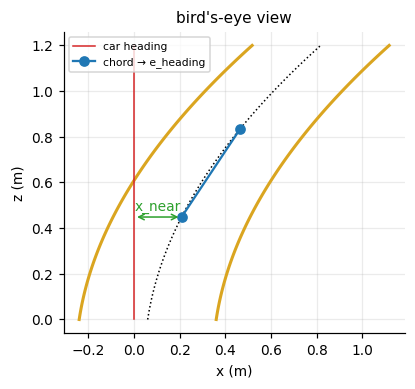

In [2]:
track = SyntheticTrack(offset=0.06, yaw=0.15, curvature=0.8)
z_n, z_f = (float(cam.distance(sum(b) / 2)) for b in ((68, 75), (52, 58)))
z = np.linspace(0, 1.2, 100)
xc = np.array([track.centre_x(t) for t in z])
pts = np.array([[track.centre_x(z_n), z_n], [track.centre_x(z_f), z_f]])

fig, ax = plt.subplots(figsize=(4, 4.4))
for s in (-1, 1):
    ax.plot(xc + s * track.half_width, z, color="goldenrod", lw=2)
ax.plot(xc, z, "k:", lw=1)
ax.plot([0, 0], [0, 1.2], color="tab:red", lw=1, label="car heading")
ax.plot(*pts.T, "o-", color="tab:blue", label="chord → e_heading")
ax.annotate("", xy=(pts[0, 0], z_n), xytext=(0, z_n), arrowprops=dict(arrowstyle="<->", color="tab:green"))
ax.text(pts[0, 0] / 2, z_n + 0.03, "x_near", color="tab:green", ha="center")
ax.set(xlabel="x (m)", ylabel="z (m)", aspect="equal", title="bird's-eye view")
ax.legend(loc="upper left", fontsize=7)
plt.show()

## State

`prev_x` keeps the last centre of each band in metres. It is the prior for the one-blob case (05) and the fallback when a band sees nothing. Stored in metres, not pixels, so one value serves any row.

This cell saves the block to `lanedet/detector.py`. The next cell imports it.

In [3]:
%%writefile lanedet/detector.py
"""Block 5 - the detector: connects mask -> scan -> centre -> camera and outputs control errors."""

import math
from dataclasses import dataclass

import numpy as np

from .camera import Camera
from .centre import BandEstimate, estimate_centre
from .mask import to_float, yellow_mask
from .scan import band_profile, find_lines


@dataclass
class Detection:
    e_lat: float  # track centre lateral offset at the near band / track half-width (+ = centre is right)
    e_heading: float  # track direction relative to the car, rad (+ = track heads right)
    confidence: float  # 0..1
    x_near: float  # m
    x_far: float  # m
    near: BandEstimate
    far: BandEstimate
    mask: np.ndarray


class LaneDetector:
    def __init__(
        self,
        camera: Camera,
        half_width: float = 0.30,
        near_rows: tuple[int, int] = (68, 75),
        far_rows: tuple[int, int] = (52, 58),
        mask_low: float = 0.15,
        mask_high: float = 0.40,
        line_level: float = 0.1,
        min_mass: float = 1.0,
        tolerance: float = 0.35,
    ):
        self.camera = camera
        self.half_width = half_width
        self.near_rows = near_rows
        self.far_rows = far_rows
        self.mask_low = mask_low
        self.mask_high = mask_high
        self.line_level = line_level
        self.min_mass = min_mass
        self.tolerance = tolerance
        self.reset()

    def reset(self) -> None:
        self.prev_x = {"near": 0.0, "far": 0.0}  # last centre estimates, m

    @staticmethod
    def band_row(rows: tuple[int, int]) -> float:
        return (rows[0] + rows[1]) / 2  # centre of rows r0..r1-1 in continuous v

    def _band(self, mask: np.ndarray, name: str, rows: tuple[int, int]) -> BandEstimate:
        v = self.band_row(rows)
        lines = find_lines(band_profile(mask, rows), self.line_level, self.min_mass)
        half_px = float(self.camera.width_px(self.half_width, v))
        prior_u = float(self.camera.to_pixel_u(self.prev_x[name], v))
        return estimate_centre(lines, half_px, prior_u, self.tolerance)

    def __call__(self, frame: np.ndarray) -> Detection:
        mask = yellow_mask(to_float(frame), self.mask_low, self.mask_high)
        near = self._band(mask, "near", self.near_rows)
        far = self._band(mask, "far", self.far_rows)

        v_near, v_far = self.band_row(self.near_rows), self.band_row(self.far_rows)
        x_near = self.prev_x["near"] if near.u is None else float(self.camera.lateral(near.u, v_near))
        x_far = self.prev_x["far"] if far.u is None else float(self.camera.lateral(far.u, v_far))
        self.prev_x = {"near": x_near, "far": x_far}

        dz = float(self.camera.distance(v_far) - self.camera.distance(v_near))
        return Detection(
            e_lat=float(np.clip(x_near / self.half_width, -1.0, 1.0)),
            e_heading=math.atan2(x_far - x_near, dz),
            confidence=(near.confidence + far.confidence) / 2,
            x_near=x_near,
            x_far=x_far,
            near=near,
            far=far,
            mask=mask,
        )

Writing lanedet/detector.py


In [4]:
from lanedet.detector import LaneDetector

def truth(track, det):
    zn = float(det.camera.distance(det.band_row(det.near_rows)))
    zf = float(det.camera.distance(det.band_row(det.far_rows)))
    xn, xf = track.centre_x(zn), track.centre_x(zf)
    return xn / track.half_width, math.atan2(xf - xn, zf - zn)

det = LaneDetector(cam)
rows = []
for name, tr in {
    "centred": SyntheticTrack(),
    "offset +0.1 m": SyntheticTrack(offset=0.1),
    "yaw −0.15": SyntheticTrack(yaw=-0.15),
    "bend right": SyntheticTrack(curvature=0.8),
    "all + noise": SyntheticTrack(offset=-0.05, yaw=0.1, curvature=-0.6, noise=12),
}.items():
    det.reset()
    d = det(tr.render(seed=0))
    tl, th = truth(tr, det)
    rows.append({"frame": name, "e_lat": d.e_lat, "true": tl, "e_heading (°)": math.degrees(d.e_heading),
                 "true (°)": math.degrees(th), "confidence": d.confidence, "near / far": f"{d.near.case} / {d.far.case}"})
table(rows)

frame,e_lat,true,e_heading (°),true (°),confidence,near / far
centred,0.000,0.000,-0.000,0.000,0.993,pair / pair
offset +0.1 m,0.334,0.333,0.148,0.000,0.881,pair / pair
yaw −0.15,-0.225,-0.226,-8.969,-8.594,0.983,pair / pair
bend right,0.267,0.268,27.406,27.181,0.993,pair / pair
all + noise,-0.220,-0.218,-16.099,-15.897,0.982,pair / pair


## Why the state matters

Drive the car from the centre across each boundary. Without state every frame uses the image centre as prior; with state each frame starts from the previous one.

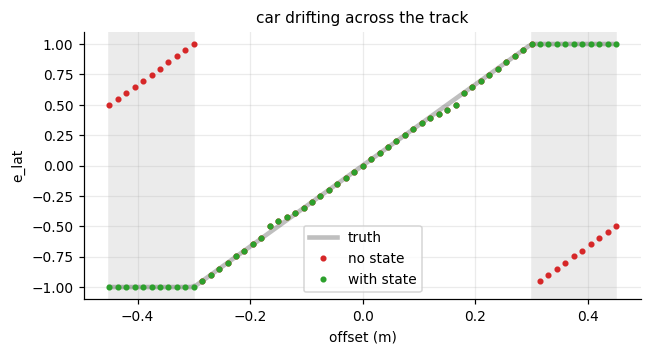

In [5]:
def sweep(tracked):
    out = {}
    for direction in (1, -1):
        det.reset()
        for o in np.linspace(0, 0.45, 31) * direction:
            if not tracked:
                det.reset()
            out[o] = det(SyntheticTrack(offset=o).render()).e_lat
    return np.array(sorted(out.items()))

o = np.linspace(-0.45, 0.45, 100)
fig, ax = plt.subplots(figsize=(6, 3.3))
ax.axvspan(-0.45, -0.3, color="0.92")
ax.axvspan(0.3, 0.45, color="0.92")
ax.plot(o, np.clip(o / 0.30, -1, 1), "k", lw=3, alpha=0.25, label="truth")
for tracked, colour in ((False, "tab:red"), (True, "tab:green")):
    s = sweep(tracked)
    ax.plot(s[:, 0], s[:, 1], ".", color=colour, label="with state" if tracked else "no state")
ax.set(xlabel="offset (m)", ylabel="e_lat", title="car drifting across the track")
ax.legend()
plt.tight_layout()
plt.show()

Shaded: the car is on or past a boundary and one line is visible. Without state the lone line is read from the wrong side and `e_lat` flips sign — a controller would steer further out. With state the estimate saturates at ±1 on the correct side.

## Check

In [6]:
det.reset()
err_lat, err_head = [], []
for frame, tr in synthetic_drive(150, noise=8):
    d = det(frame)
    tl, th = truth(tr, det)
    err_lat.append(d.e_lat - tl)
    err_head.append(d.e_heading - th)
assert np.sqrt(np.mean(np.square(err_lat))) < 0.03
assert math.degrees(np.sqrt(np.mean(np.square(err_head)))) < 1.5
s = sweep(True)
assert s[0, 1] == -1.0 and s[-1, 1] == 1.0

## Exercises

1. Call `det.reset()` before every frame of the drive. How much do the errors grow?
2. Lower `confidence` when the new centre jumps more than 5 cm from `prev_x`. Where would that help?